# L7 Hackathon

# Libraries

In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from pandas.core.reshape import encoding
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Data

In [2]:
# Add your code here
df = pd.read_csv('data/corona_tested_individuals_ver_006.english.csv')
df.head()

/tmp/ipykernel_36/2668654382.py:2: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/corona_tested_individuals_ver_006.english.csv')


,test_date,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,age_60_and_above,gender,test_indication
0,2020-04-30,0.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
1,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
2,2020-04-30,0.0,1.0,0.0,0.0,0.0,negative,NaN,male,Other
3,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
4,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,male,Other


# Cleaning data

In [8]:
df_clean = df.copy()

#Ignore age 60 and above and gender columns
df_clean.drop(['test_date', 'age_60_and_above', 'gender'], axis=1, inplace=True)

#drops rows with null in other symptoms
df_clean.dropna(subset=['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache'], inplace=True)

#corona result is our target. it has positive, negative and other. Other is abt 1%
#drop other for now
if 'other' in df_clean['corona_result'].unique():
    df_clean = df_clean[df_clean['corona_result'] != 'other']

df_clean.head()


,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,test_indication
0,0.0,0.0,0.0,0.0,0.0,negative,Other
1,1.0,0.0,0.0,0.0,0.0,negative,Other
2,0.0,1.0,0.0,0.0,0.0,negative,Other
3,1.0,0.0,0.0,0.0,0.0,negative,Other
4,1.0,0.0,0.0,0.0,0.0,negative,Other


In [ ]:
# Categorise the features
df_cat = df_clean.copy()

#corona result is our target. it has positive, negative and other. make 1 for positive, 0 for the rest
df_cat["corona_result"] = (df_cat['corona_result']=='positive').astype(int)

# test indication - categorise 'other', 'abroard' and 'contact with get dummies

encoded_df = pd.get_dummies(
    df_cat,
    columns=['test_indication'],
    dtype=int
)

# Check the class balance
encoded_df.value_counts()


# Baseline Model

The original Baseline Model

In [28]:
''''Simple decision tree for baseline model'''

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

y = encoded_df['corona_result']
X = encoded_df.drop('corona_result', axis=1)


#need to stratify as imbalanced to make pos/neg spread even in train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [12]:
#Fit to simple decision tree
dtc = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42)
dtc.fit(X_train, y_train)

y_pred = dtc.predict(X_test)
y_prob = dtc.predict_proba(X_test)[:, 1]


In [14]:
print('Accuracy :', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred))
print('ROC AUC  :', roc_auc_score(y_test, y_prob))

from sklearn.metrics import classification_report

y_pred = dtc.predict(X_test)

print(classification_report(y_test, y_pred))



Accuracy : 0.8933219271582242
Precision: 0.3088697017268446
Recall: 0.8033344675059544
F1: 0.44618728148918074
ROC AUC  : 0.8945130018882332
              precision    recall  f1-score   support

           0       0.99      0.90      0.94     52002
           1       0.31      0.80      0.45      2939

    accuracy                           0.89     54941
   macro avg       0.65      0.85      0.69     54941
weighted avg       0.95      0.89      0.91     54941



Baseline is bad at recall of positives. We want to prioritise catching positives (1) over false negatives

              precision    recall  f1-score   support

           0       0.99      0.90      0.94     52002
           1       0.31      0.80      0.45      2939

    accuracy                           0.89     54941
   macro avg       0.65      0.85      0.69     54941
weighted avg       0.95      0.89      0.91     54941



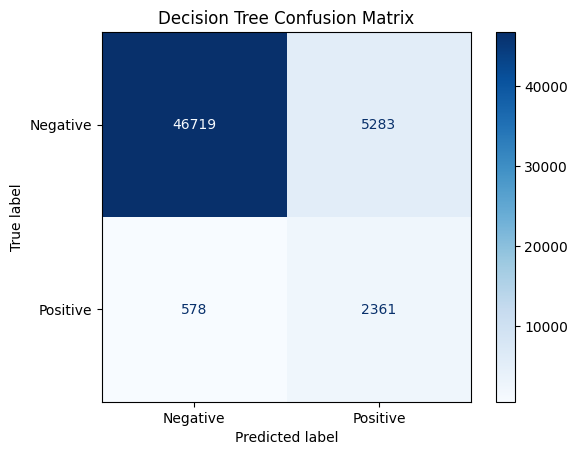

In [15]:
from sklearn.metrics import classification_report

y_pred = dtc.predict(X_test)

print(classification_report(y_test, y_pred))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=['Negative', 'Positive']

)

disp.plot(cmap='Blues')

plt.title('Baseline Decision Tree Confusion Matrix')

plt.show()


The model identified only 53% of the people who were actually positive.
Put another way, of 2,939 actual positives: it correctly detected 1,571 and it missed 1,368, so it's missing roughly 47% of the positive cases. We want to improve this so catch more true positives.

# Random Forest Classifier

In [60]:
#Create new feature for number of symptoms
# Count the number of symptoms reported by each person
encoded_df['number_of_symptoms'] = encoded_df[symptoms].sum(axis=1)

# Check the new feature
encoded_df['number_of_symptoms'].value_counts().sort_index()

number_of_symptoms
0.0    225931
1.0     31420
2.0     15360
3.0      1443
4.0       455
5.0        93
Name: count, dtype: int64

In [65]:
y = encoded_df['corona_result']
X = encoded_df.drop('corona_result', axis=1)

#need to stratify as imbalanced to make pos/neg spread even in train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


# Second split: 60% training, 20% validation, 20% test
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

In [52]:
'''Train a Random Forest'''

# Create random forest model
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train the model
rf.fit(X_train_new, y_train_new)

# Make predictions
rf_pred = rf.predict(X_val)

# Predict probability of positive COVID-19
rf_prob = rf.predict_proba(X_val)[:, 1]


In [53]:
'''Evaluate the model'''

print("RANDOM FOREST RESULTS")
print("---------------------")

print("Accuracy :", accuracy_score(y_val, rf_pred))
print("Precision:", precision_score(y_val, rf_pred))
print("Recall   :", recall_score(y_val, rf_pred))
print("F1       :", f1_score(y_val, rf_pred))
print("ROC-AUC  :", roc_auc_score(y_val, rf_prob))

print("\nClassification Report:")
print(classification_report(y_val, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_pred))


RANDOM FOREST RESULTS
---------------------
Accuracy : 0.907300558781238
Precision: 0.3403971547125074
Recall   : 0.7815583531813542
F1       : 0.47424383193971303
ROC-AUC  : 0.8982736013542756

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.91      0.95     52002
           1       0.34      0.78      0.47      2939

    accuracy                           0.91     54941
   macro avg       0.66      0.85      0.71     54941
weighted avg       0.95      0.91      0.92     54941


Confusion Matrix:
[[47551  4451]
 [  642  2297]]


In [57]:

# Compare model performance
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_val, rf_prob)
    ],
    'Precision': [
        precision_score(y_test, y_pred),
        precision_score(y_val, rf_pred)
    ],
    'Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_val, rf_pred)
    ],
    'False Negatives': [
        confusion_matrix(y_test, y_pred)[1, 0],
        confusion_matrix(y_val, rf_pred)[1, 0]
    ]
})

comparison


,Model,ROC-AUC,Precision,Recall,False Negatives
0,Decision Tree,0.894513,0.308870,0.803334,578
1,Random Forest,0.898274,0.340397,0.781558,642


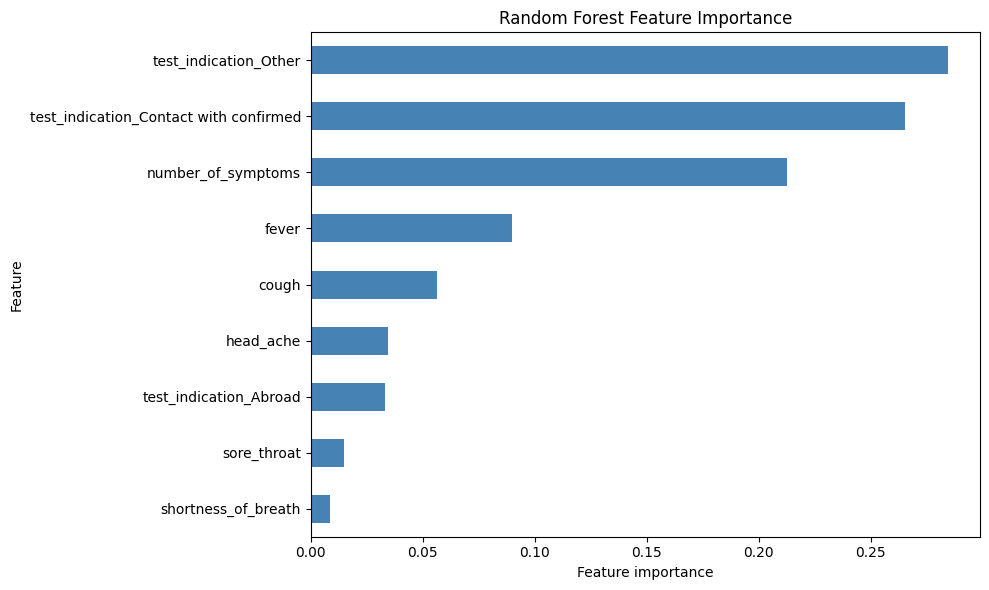

In [58]:
#What is the most important feature

importance = pd.Series(
    rf.feature_importances_,
    index=X_train_new.columns
).sort_values()

plt.figure(figsize=(10, 6))

importance.plot(kind='barh', color='steelblue')

plt.title('Random Forest Feature Importance')
plt.xlabel('Feature importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()


In [66]:
'''Investigate whether lowering its classification threshold improves recall'''


results = []

for threshold in [0.1, 0.15, 0.2, 0.3, 0.4, 0.5]:
    predictions = (rf_prob >= threshold).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, predictions, zero_division=0),
        'Recall': recall_score(y_val, predictions),
        'False Negatives': confusion_matrix(y_val, predictions)[1, 0]
    })

pd.DataFrame(results)


,Threshold,Precision,Recall,False Negatives
0,0.10,0.053494,1.000000,0
1,0.15,0.053494,1.000000,0
2,0.20,0.224442,0.856073,423
3,0.30,0.224442,0.856073,423
4,0.40,0.275130,0.825111,514
5,0.50,0.340397,0.781558,642


In [68]:
# Compare model performance
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'Random Forest (threshold: 0.2)'],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_val, rf_prob),
        roc_auc_score(y_val, (rf_prob>=0.2).astype(int))
    ],
    'Precision': [
        precision_score(y_test, y_pred),
        precision_score(y_val, rf_pred),
        precision_score(y_val, (rf_prob>=0.2).astype(int), zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_val, rf_pred),
        recall_score(y_val, (rf_prob>=0.2).astype(int))
    ],
    'False Negatives': [
        confusion_matrix(y_test, y_pred)[1, 0],
        confusion_matrix(y_val, rf_pred)[1, 0],
        confusion_matrix(y_val, (rf_prob>=0.2).astype(int))[1, 0]
    ]
})

comparison

,Model,ROC-AUC,Precision,Recall,False Negatives
0,Decision Tree,0.894513,0.308870,0.803334,578
1,Random Forest,0.898274,0.340397,0.781558,642
2,Random Forest (threshold: 0.2),0.844444,0.224442,0.856073,423


In [69]:
'''Improving with Random Forest with cross-validation'''

# Define the model
rf_cv = RandomForestClassifier(
    random_state=42,
    class_weight='balanced',
    n_jobs=1
)

# Define hyperparameters to explore
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 5, 10],
    'class_weight': [None, 'balanced']
}

# Stratified cross-validation preserves class proportions
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Random search
random_search = RandomizedSearchCV(
    estimator=rf_cv,
    param_distributions=param_grid,
    n_iter=10,
    scoring='recall', # to improve recall
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Use training data only
random_search.fit(X_train_new, y_train_new)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(random_search.best_score_)

'''
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 5, 'class_weight': 'balanced'}

Best cross-validation ROC-AUC:
0.818739573727014
'''


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 5, 'class_weight': 'balanced'}

Best cross-validation ROC-AUC:
0.818739573727014


In [70]:
best_rf = random_search.best_estimator_

# Validation predictions
best_prob = best_rf.predict_proba(X_val)[:, 1]
best_pred = best_rf.predict(X_val)

In [71]:
results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    pred = (best_prob >= threshold).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, pred, zero_division=0),
        'Recall': recall_score(y_val, pred),
        'False Negatives': confusion_matrix(y_val, pred)[1, 0]
    })
    
pd.DataFrame(results)

,Threshold,Precision,Recall,False Negatives
0,0.1,0.053494,1.000000,0
1,0.2,0.224442,0.856073,423
2,0.3,0.224442,0.856073,423
3,0.4,0.224442,0.856073,423
4,0.5,0.275295,0.825791,512


In [27]:

# # Create SHAP explainer
#%pip install shap
#import shap
# explainer_rf = shap.TreeExplainer(best_rf)

# # Sample 500 observations from validation data
# X_sample_rf = X_val.sample(
#     n=min(500, len(X_val)),
#     random_state=42
# )

# # Calculate SHAP values
# shap_values_rf = explainer_rf(X_sample_rf)

# # Select positive COVID-19 class
# positive_index = list(best_rf.classes_).index(1)

# if shap_values_rf.values.ndim == 3:
#     positive_shap_rf = shap_values_rf[:, :, positive_index]
# else:
#     positive_shap_rf = shap_values_rf

# print("SHAP values shape:", positive_shap_rf.values.shape)


NameError: name 'shap' is not defined

In [ ]:

# shap.plots.bar(
#     positive_shap_rf,
#     max_display=10
# )


In [ ]:

# shap.plots.beeswarm(
#     positive_shap_rf,
#     max_display=10
# )


In [76]:

results = []

models = [
    ('Original Random Forest', rf, 0.5),
    ('Original RF - Threshold 0.2', rf, 0.2),
    ('Optimised Random Forest', best_rf, 0.5),
    ('Optimised RF - Threshold 0.2', best_rf, 0.2)
]

for name, model, threshold in models:

    # Predict probabilities
    probabilities = model.predict_proba(X_val)[:, 1]

    # Apply classification threshold
    predictions = (probabilities >= threshold).astype(int)

    results.append({
        'Model': name,
        'ROC-AUC': roc_auc_score(y_val, probabilities),
        'Precision': precision_score(
            y_val, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_val, predictions, zero_division=0
        ),
        'False Negatives': confusion_matrix(
            y_val, predictions, labels=[0, 1]
        )[1, 0]
    })

comparison_updated = pd.DataFrame(results)

comparison_updated.round(4)


,Model,ROC-AUC,Precision,Recall,False Negatives
0,Original Random Forest,0.8983,0.3404,0.7816,642
1,Original RF - Threshold 0.2,0.8983,0.2244,0.8561,423
2,Optimised Random Forest,0.8979,0.2753,0.8258,512
3,Optimised RF - Threshold 0.2,0.8979,0.2244,0.8561,423


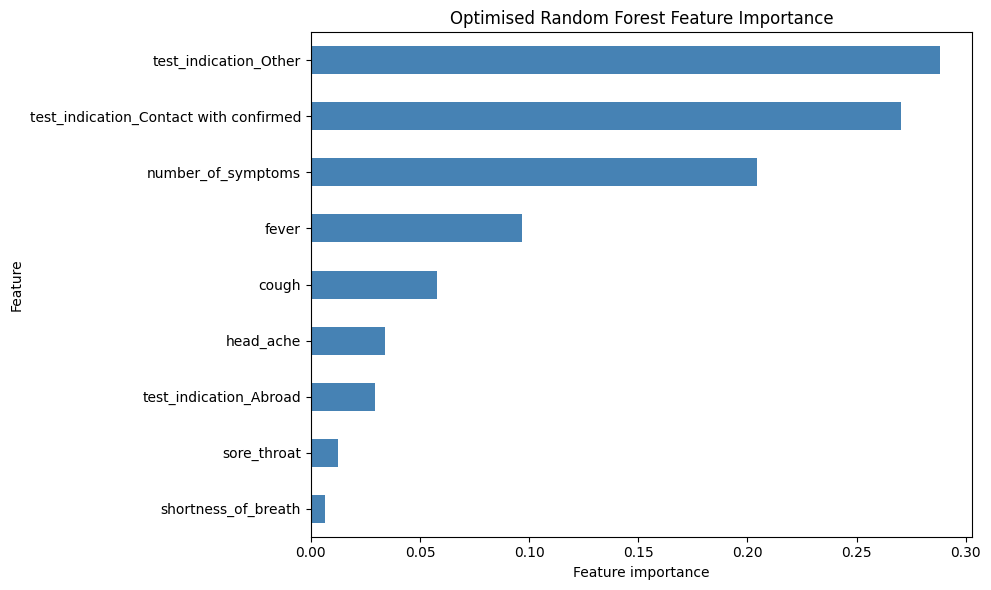

In [73]:
#What is the most important feature

importance = pd.Series(
    best_rf.feature_importances_,
    index=X_train_new.columns
).sort_values()

plt.figure(figsize=(10, 6))

importance.plot(kind='barh', color='steelblue')

plt.title('Optimised Random Forest Feature Importance')
plt.xlabel('Feature importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()


SHAP identified testing indication as the most influential features overall.
Fever was the most influential individual symptom on average. Headache, sore throat and shortness of breath had lower average importance but substantially influenced some individual predictions.
These findings raise questions about potential reporting bias, particularly for symptoms identified in the original research.

The random forest achieved good discrimination between positive and negative COVID-19 cases, with ROC-AUC close to 0.90, Pecision 0.2244, Recall 0.8561 and False negatives	423.
Hyperparameter optimisation offered little additional benefit, whereas adjusting the classification threshold substantially improved recall.

My recommendation is to retain the random forest as a candidate model and consider a lower classification threshold for screening purposes, subject to comparison with logistic regression and LightGBM.

The next step is to compare all models on the same validation dataset, agree an appropriate balance between precision and recall, and evaluate the selected model on an untouched test set.